# Bài 7 (Trang 27 - 31): Nhận dạng chữ số viết tay (MNIST - `load_digits`)
**Sinh viên:** Trần Nhất Long - 6451071042

### 1. Chuẩn bị thư viện và tải dữ liệu `digits`

In [1]:
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageOps

from sklearn import datasets, tree, metrics
from sklearn.model_selection import train_test_split

print("Trần Nhất Long - 6451071042")
digits = datasets.load_digits()
print("Kích thước digits.images:", digits.images.shape)
print("Số lượng nhãn:", len(digits.target))

Trần Nhất Long - 6451071042
Kích thước digits.images: (1797, 8, 8)
Số lượng nhãn: 1797


### 2. Biểu diễn 4 mẫu dữ liệu huấn luyện tương ứng với 4 lớp 0, 1, 2, 3

Trần Nhất Long - 6451071042


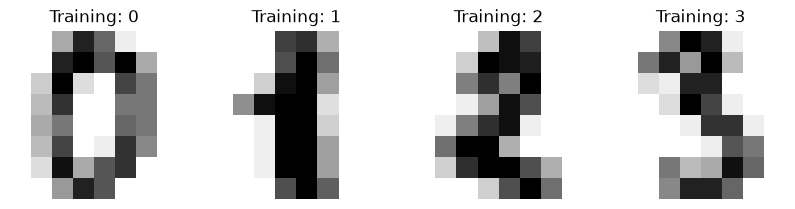

In [2]:
print("Trần Nhất Long - 6451071042")
_, axes = plt.subplots(1, 4, figsize=(10, 3))
images_and_labels = list(zip(digits.images, digits.target))
for ax, (image, label) in zip(axes, images_and_labels[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation="nearest")
    ax.set_title("Training: %i" % label)
plt.show()

### 3. Chuyển đổi ma trận 8x8 thành vector 1x64, chia dữ liệu 80/20 và huấn luyện cây ID3

In [3]:
print("Trần Nhất Long - 6451071042")
n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))

classifier = tree.DecisionTreeClassifier(criterion="entropy", random_state=33)

X_train, X_test, y_train, y_test = train_test_split(
    data, digits.target, test_size=0.2, shuffle=False
)
print("Số mẫu huấn luyện:", len(X_train), "| Số mẫu kiểm thử:", len(X_test))

classifier.fit(X_train, y_train)

Trần Nhất Long - 6451071042
Số mẫu huấn luyện: 1437 | Số mẫu kiểm thử: 360


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",33
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsampl

### 4. Dự đoán trên tập kiểm thử, biểu diễn kết quả và đánh giá bằng ma trận nhầm lẫn

Trần Nhất Long - 6451071042


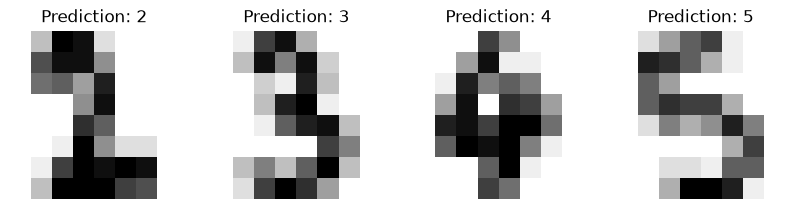

Classification report for classifier DecisionTreeClassifier(criterion='entropy', random_state=33):
              precision    recall  f1-score   support

           0       0.86      0.89      0.87        35
           1       0.72      0.64      0.68        36
           2       0.76      0.74      0.75        35
           3       0.69      0.59      0.64        37
           4       0.86      0.84      0.85        37
           5       0.80      0.95      0.86        37
           6       0.97      0.95      0.96        37
           7       0.78      0.86      0.82        36
           8       0.79      0.82      0.81        33
           9       0.72      0.70      0.71        37

    accuracy                           0.80       360
   macro avg       0.80      0.80      0.79       360
weighted avg       0.80      0.80      0.79       360




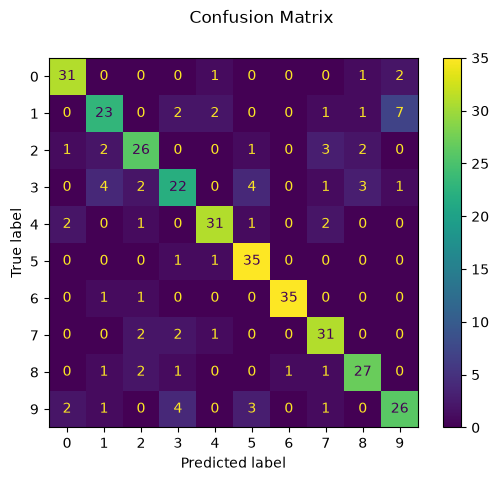

Confusion matrix:
[[31  0  0  0  1  0  0  0  1  2]
 [ 0 23  0  2  2  0  0  1  1  7]
 [ 1  2 26  0  0  1  0  3  2  0]
 [ 0  4  2 22  0  4  0  1  3  1]
 [ 2  0  1  0 31  1  0  2  0  0]
 [ 0  0  0  1  1 35  0  0  0  0]
 [ 0  1  1  0  0  0 35  0  0  0]
 [ 0  0  2  2  1  0  0 31  0  0]
 [ 0  1  2  1  0  0  1  1 27  0]
 [ 2  1  0  4  0  3  0  1  0 26]]


In [4]:
print("Trần Nhất Long - 6451071042")
predicted = classifier.predict(X_test)

_, axes = plt.subplots(1, 4, figsize=(10, 3))
test_images = X_test.reshape((-1, 8, 8))
images_and_predictions = list(zip(test_images, predicted))
for ax, (image, prediction) in zip(axes, images_and_predictions[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation="nearest")
    ax.set_title("Prediction: %i" % prediction)
plt.show()

print("Classification report for classifier %s:\n%s\n"
      % (classifier, metrics.classification_report(y_test, predicted)))

disp = metrics.ConfusionMatrixDisplay.from_estimator(classifier, X_test, y_test)
disp.figure_.suptitle("Confusion Matrix")
plt.show()
print("Confusion matrix:\n%s" % disp.confusion_matrix)

### 5. Nhận dạng chữ số viết tay từ ảnh thực tế (`test_image_Bai7_1.jpg` và `test_image_Bai7_2.jpg`)

Trần Nhất Long - 6451071042
File: test_image_Bai7_1.jpg -> Giá trị vector sau làm rõ nét:
[[  0   0   0   0 155   0   0   0   0   0   0   0 155   0   0   0   0   0
    0 155 155   0   0   0   0   0   0 155 155   0   0   0   0   0   0   0
  155   0   0   0   0   0   0   0 155   0   0   0   0   0   0   0 155   0
    0   0   0   0   0 155 155   0   0   0]]
Kết quả nhận dạng bằng cây ID3: [1]



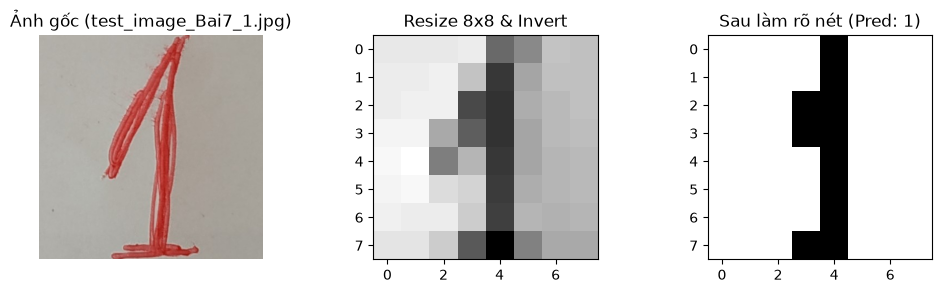

File: test_image_Bai7_2.jpg -> Giá trị vector sau làm rõ nét:
[[  0   0 155 155 155   0   0   0   0   0 155   0   0 155   0   0   0   0
  155   0   0 155   0   0   0   0 155   0 155 155   0   0   0   0   0   0
  155   0   0   0   0   0   0 155   0   0   0   0   0   0 155 155   0 155
    0   0   0   0 155 155 155 155   0   0]]
Kết quả nhận dạng bằng cây ID3: [2]



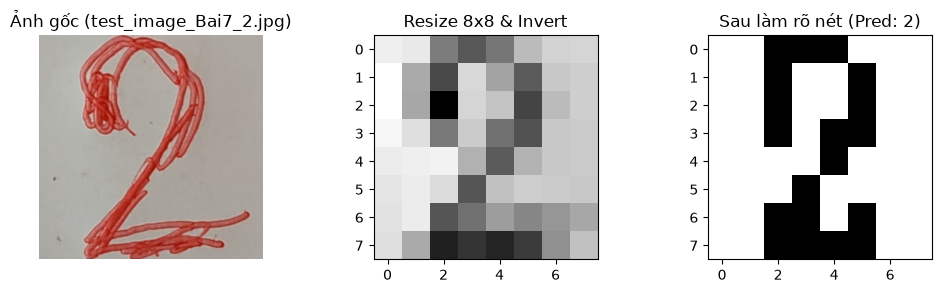

In [5]:
print("Trần Nhất Long - 6451071042")
test_files = ["test_image_Bai7_1.jpg", "test_image_Bai7_2.jpg"]

for fname in test_files:
    orig = Image.open(fname)
    img = orig.convert("L").resize((8, 8))
    img_inv = ImageOps.invert(img)
    im2arr = np.array(img_inv)

    img1d = im2arr.reshape([1, 64]).copy()
    img1d[img1d > 109] = 155
    img1d[img1d < 110] = 0
    norm_2d = img1d.reshape((8, 8))

    y_pred = classifier.predict(img1d)
    print(f"File: {fname} -> Giá trị vector sau làm rõ nét:")
    print(img1d)
    print(f"Kết quả nhận dạng bằng cây ID3: {y_pred}\n")

    fig, axes = plt.subplots(1, 3, figsize=(10, 3))
    axes[0].imshow(orig)
    axes[0].set_title(f"Ảnh gốc ({fname})")
    axes[0].set_axis_off()

    axes[1].imshow(im2arr, cmap=plt.cm.gray_r, interpolation="nearest")
    axes[1].set_title("Resize 8x8 & Invert")

    axes[2].imshow(norm_2d, cmap=plt.cm.gray_r, interpolation="nearest")
    axes[2].set_title(f"Sau làm rõ nét (Pred: {y_pred[0]})")
    plt.tight_layout()
    plt.show()